In [2]:
import sys
sys.path.append("..")

from project1.data import load_data, EMOTIONS
from collections import Counter, OrderedDict
import part1
from project1 import encoders, experiments
import numpy as np

In [3]:
# loading data and print data info

dataset, outcome_space = load_data(test_size=0.2, seed=0)

train_texts  = dataset["train"]["text"]
train_labels = dataset["train"]["label"]
pairs  = list(zip(train_texts, train_labels))   

print(dataset)                              
print("example sentence:" , dataset["train"][0])                   
print("class id and their counts:", Counter(dataset["train"]["label"]))   
print("outcome space:", [outcome_space.name(i) for i in range(len(EMOTIONS))]) 
print("first 20 (text, label) pairs:", pairs[0:20])

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 6012
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 1504
    })
})
example sentence: {'text': 'Grovelling people.', 'label': 4}
class id and their counts: Counter({0: 877, 1: 868, 5: 863, 3: 858, 6: 853, 2: 848, 4: 845})
outcome space: ['joy', 'fear', 'anger', 'sadness', 'disgust', 'shame', 'guilt']
first 20 (text, label) pairs: [('Grovelling people.', 4), ('My sweatheart were away on a trip, and then she got problems.', 3), ('When a close friend, residing in the hostel, lost his father I  \nreally pittied him and the situation made me feel sad.', 3), ('Receiving a postcard form my sweetheart who was abroad on  \nvacation, not being at all sure if he would write me or not.', 0), ('When my father made my mother go through really terrible  \nsituations, I felt furious, impotent, nervous, upset, ........', 2), ('When I realized that I was far behind the others in th

In [4]:
# implement tokenizer and encoders
tokenizer = part1.experiment.train_tokenizer(
  train_texts,
  vocab_size=5000,
  min_frequency=2
)

In [5]:
# encoder representations
representations = {
  "indicator": encoders.TokenIndicator(tokenizer),
  "bow": encoders.BagOfWords(tokenizer),
  "tfidf": encoders.TfIdf(tokenizer, train_texts)
}

# classification architectures --- we choose dropout 0.5 weight decay 0.1
architectures = {
    "logistic": dict(model_option="logistic", loglin_args={"max_iter": 200}),
    "mlp": dict(model_option="mlp", smlp_args=dict(hidden_dim=128, dropout=.5, weight_decay=.1, num_epochs=20)),
    "mlp_tuned": dict(model_option="mlp2", mlp2_args=dict(hidden_dim=128, second_hidden_dim=64, patience=3, dropout=.5, weight_decay=.1, num_epochs=20)),
}

In [6]:
# run experiments on all combinations of representations and architectures
my_classifiers = experiments.run_experiments(representations, architectures, pairs, outcome_space, seeds=(0,1,2))

  0%|          | 0/5 [00:00<?, ?it/s]

/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/lin

  0%|          | 0/5 [00:00<?, ?it/s]

/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/lin

  0%|          | 0/5 [00:00<?, ?it/s]

/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/lin

... (118 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9341 | train acc: 0.2200 | val loss: 1.9069 | val acc: 0.3918
Epoch 02 | train loss: 1.8148 | train acc: 0.5358 | val loss: 1.7625 | val acc: 0.5200
Epoch 03 | train loss: 1.5355 | train acc: 0.6518 | val loss: 1.5683 | val acc: 0.5399
Epoch 04 | train loss: 1.2172 | train acc: 0.7299 | val loss: 1.4352 | val acc: 0.5483
Epoch 05 | train loss: 0.9581 | train acc: 0.7938 | val loss: 1.3648 | val acc: 0.5441
Epoch 06 | train loss: 0.7797 | train acc: 0.8297 | val loss: 1.3354 | val acc: 0.5466
Epoch 07 | train loss: 0.6358 | train acc: 0.8678 | val loss: 1.3290 | val acc: 0.5474
Epoch 08 | train loss: 0.5248 | train acc: 0.9000 | val loss: 1.3385 | val acc: 0.5458
Epoch 09 | train loss: 0.4424 | train acc: 0.9210 | val loss: 1.3607 | val acc: 0.5374
Epoch 10 | train loss: 0.3775 | train acc: 0.9403 | val loss: 1.3840 | val acc: 0.5366
Epoch 11 | train loss: 0.3185 | train acc: 0.9511 | val loss: 1.4142 | val acc: 0.5324
Epoch 12 | train loss: 0.2754 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9354 | train acc: 0.2021 | val loss: 1.9130 | val acc: 0.3636
Epoch 02 | train loss: 1.8245 | train acc: 0.5191 | val loss: 1.7719 | val acc: 0.4842
Epoch 03 | train loss: 1.5463 | train acc: 0.6393 | val loss: 1.5683 | val acc: 0.5300
Epoch 04 | train loss: 1.2206 | train acc: 0.7293 | val loss: 1.4228 | val acc: 0.5341
Epoch 05 | train loss: 0.9698 | train acc: 0.7865 | val loss: 1.3518 | val acc: 0.5358
Epoch 06 | train loss: 0.7751 | train acc: 0.8376 | val loss: 1.3129 | val acc: 0.5441
Epoch 07 | train loss: 0.6310 | train acc: 0.8694 | val loss: 1.3039 | val acc: 0.5549
Epoch 08 | train loss: 0.5197 | train acc: 0.9004 | val loss: 1.3087 | val acc: 0.5491
Epoch 09 | train loss: 0.4424 | train acc: 0.9187 | val loss: 1.3230 | val acc: 0.5474
Epoch 10 | train loss: 0.3714 | train acc: 0.9385 | val loss: 1.3464 | val acc: 0.5433
Epoch 11 | train loss: 0.3224 | train acc: 0.9493 | val loss: 1.3649 | val acc: 0.5458
Epoch 12 | train loss: 0.2729 | train acc: 

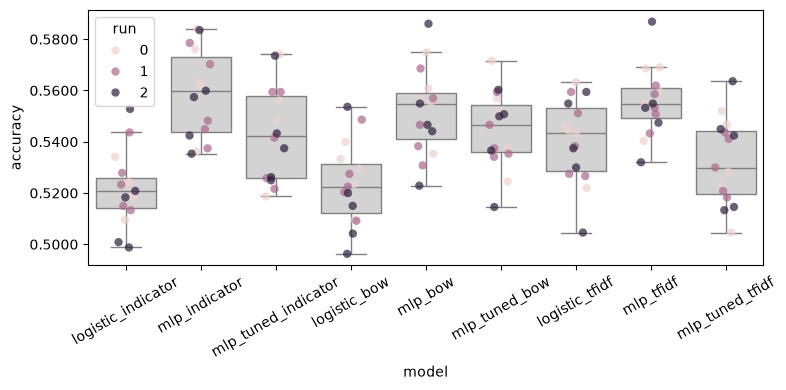

In [7]:
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))

A=logistic_indicator B=mlp_indicator: P(A wins)=0.0000 P(Tie)=0.0001 P(B wins)=0.9999 Effect Size=6.10


,A,B,acc_A,acc_B,diff (B-A),P(A wins),P(tie),P(B wins),effect size,most probable
0,logistic_indicator,mlp_indicator,0.5217,0.5586,0.0369,0.0000,0.0001,0.9999,6.1040,mlp_indicator wint
1,logistic_indicator,mlp_tuned_indicator,0.5217,0.5435,0.0218,0.0010,0.0149,0.9841,3.0916,mlp_tuned_indicator wint
2,logistic_indicator,logistic_bow,0.5217,0.5235,0.0018,0.1036,0.6218,0.2746,0.3543,gelijk
3,logistic_indicator,mlp_bow,0.5217,0.5519,0.0302,0.0000,0.0004,0.9996,5.1239,mlp_bow wint
4,logistic_indicator,mlp_tuned_bow,0.5217,0.5445,0.0228,0.0011,0.0145,0.9844,3.0676,mlp_tuned_bow wint
5,logistic_indicator,logistic_tfidf,0.5217,0.5405,0.0189,0.0001,0.0052,0.9947,4.0164,logistic_tfidf wint
6,logistic_indicator,mlp_tfidf,0.5217,0.5557,0.0340,0.0000,0.0000,1.0000,6.4915,mlp_tfidf wint
7,logistic_indicator,mlp_tuned_tfidf,0.5217,0.5325,0.0108,0.0169,0.1839,0.7993,1.6096,mlp_tuned_tfidf wint
8,mlp_indicator,mlp_tuned_indicator,0.5586,0.5435,-0.0151,0.9820,0.0178,0.0002,-3.4714,mlp_indicator wint
9,mlp_indicator,logistic_bow,0.5586,0.5235,-0.0351,0.9999,0.0001,0.0000,-5.6186,mlp_indicator wint


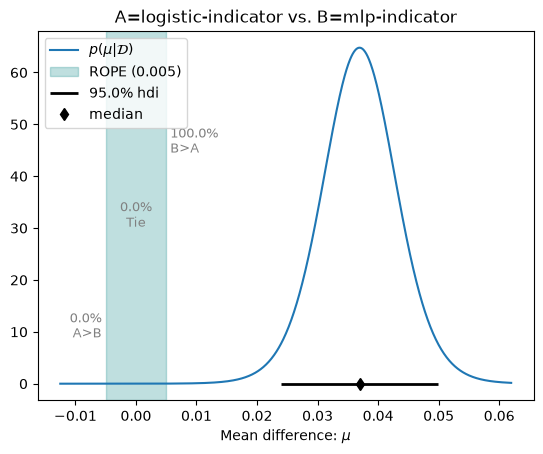

In [9]:
from itertools import combinations
import pandas as pd

# First, a little helper, to gather all accuracies across runs and folds
def get_all_measurements_for(data, sys_name):
    return np.array([list(run_data['accuracies'].values()) for run_data in data[sys_name]])

############################################################################################################################################
# visualization of 1 setting
############################################################################################################################################

# this will have shape [num_runs, num_folds]
get_all_measurements_for(my_classifiers, 'logistic_indicator')

posterior = part1.analysis.BenavoliCorrelatedT(
    get_all_measurements_for(my_classifiers, 'logistic_indicator').flatten(),  # [num_runs * num_folds]
    get_all_measurements_for(my_classifiers, 'mlp_indicator').flatten(),  # [num_runs * num_folds]
    runs=get_all_measurements_for(my_classifiers, 'logistic_indicator').shape[0],
    names=["logistic-indicator", "mlp-indicator"]
)
p_a, p_tie, p_b = posterior.probs(0.005) # rope = 0.5%
print(f"A=logistic_indicator B=mlp_indicator: P(A wins)={p_a:.4f} P(Tie)={p_tie:.4f} P(B wins)={p_b:.4f} Effect Size={posterior.effect_size:.2f}")
# if you need to zoom in or out reduce/increase the argument rope_factor (it doesn't affect the ROPE, only the visualisation of it)
_ = posterior.plot(0.005)  

############################################################################################################################################

def compare_all(data, rope=0.005, plot=False):
    rows = []
    for a, b in combinations(data.keys(), 2):
        acc_a = get_all_measurements_for(data, a)
        acc_b = get_all_measurements_for(data, b)

        posterior = part1.analysis.BenavoliCorrelatedT(
            acc_a.flatten(), acc_b.flatten(),
            runs=acc_a.shape[0],   # number of seeds
            names=[a, b]
        )
        p_a, p_tie, p_b = posterior.probs(rope)
        verdict = {0: f"{a} wint", 1: "gelijk", 2: f"{b} wint"}[int(np.argmax([p_a, p_tie, p_b]))]

        rows.append({
            "A": a, "B": b,
            "acc_A": acc_a.mean(), "acc_B": acc_b.mean(),
            "diff (B-A)": posterior.mean_diff,
            "P(A wins)": p_a, "P(tie)": p_tie, "P(B wins)": p_b,
            "effect size": posterior.effect_size,
            "most probable": verdict,
        })

        if plot:
            posterior.plot(rope)
            plt.show()

    return pd.DataFrame(rows)

results_df = compare_all(my_classifiers, rope=0.005)
results_df.round(4)

In [11]:
# Final run: mean validation accuracy per system (3 seeds x 5 folds = 15 measurements)
ARCH_NAMES = {"logistic": "Logistic", "mlp": "MLP", "mlp_tuned": "mlp2"}
REP_NAMES = {"indicator": "Indicator", "bow": "BoW", "tfidf": "TF-IDF"}

rows = []
for sys_name in my_classifiers:
    arch, rep = sys_name.rsplit("_", 1)          # "mlp_tuned_bow" -> "mlp_tuned", "bow"
    acc = get_all_measurements_for(my_classifiers, sys_name).flatten()
    rows.append({
        "architecture": ARCH_NAMES[arch],
        "representation": REP_NAMES[rep],
        "accuracy": acc.mean(),
    })
summary_df = pd.DataFrame(rows)

final_table = (summary_df
               .pivot(index="architecture", columns="representation", values="accuracy")
               .reindex(index=list(ARCH_NAMES.values()), columns=list(REP_NAMES.values())))

print("Mean validation accuracy (15 measurements per system)")
display(final_table.round(4))

best = summary_df.loc[summary_df["accuracy"].idxmax()]
print(f"Best system: {best.architecture} + {best.representation} ({best.accuracy:.4f})")

Mean validation accuracy (15 measurements per system)


representation,Indicator,BoW,TF-IDF
architecture,,,
Logistic,0.5217,0.5235,0.5405
MLP,0.5586,0.5519,0.5557
mlp2,0.5435,0.5445,0.5325


Best system: MLP + Indicator (0.5586)


In [12]:
# Keep only pairs that differ in exactly one factor (architecture OR representation)
df = results_df.copy()
for col in ["A", "B"]:
    df[col] = df[col].str.replace("mlp_tuned", "mlp2")              # same name as in the documentation
    df[f"arch_{col}"] = df[col].str.rsplit("_", n=1).str[0]
    df[f"rep_{col}"] = df[col].str.rsplit("_", n=1).str[1]

def verdict(row):
    i = int(np.argmax([row["P(A wins)"], row["P(tie)"], row["P(B wins)"]]))
    return [f"{row['A']} better", "practically equal", f"{row['B']} better"][i]

df["most probable"] = df.apply(verdict, axis=1)

columns = ["A", "B", "acc_A", "acc_B", "diff (B-A)", "P(A wins)", "P(tie)", "P(B wins)", "most probable"]

rep_effect = df[(df["arch_A"] == df["arch_B"]) & (df["rep_A"] != df["rep_B"])][columns]
arch_effect = df[(df["rep_A"] == df["rep_B"]) & (df["arch_A"] != df["arch_B"])][columns]

print("Effect of representation (same architecture), ROPE = 0.005")
display(rep_effect.round(4).reset_index(drop=True))

print("Effect of architecture (same representation), ROPE = 0.005")
display(arch_effect.round(4).reset_index(drop=True))

Effect of representation (same architecture), ROPE = 0.005


,A,B,acc_A,acc_B,diff (B-A),P(A wins),P(tie),P(B wins),most probable
0,logistic_indicator,logistic_bow,0.5217,0.5235,0.0018,0.1036,0.6218,0.2746,practically equal
1,logistic_indicator,logistic_tfidf,0.5217,0.5405,0.0189,0.0001,0.0052,0.9947,logistic_tfidf better
2,mlp_indicator,mlp_bow,0.5586,0.5519,-0.0067,0.6437,0.3453,0.0110,mlp_indicator better
3,mlp_indicator,mlp_tfidf,0.5586,0.5557,-0.0029,0.3405,0.5954,0.0642,practically equal
4,mlp2_indicator,mlp2_bow,0.5435,0.5445,0.0009,0.2035,0.5119,0.2846,practically equal
5,mlp2_indicator,mlp2_tfidf,0.5435,0.5325,-0.0110,0.8099,0.1749,0.0152,mlp2_indicator better
6,logistic_bow,logistic_tfidf,0.5235,0.5405,0.0170,0.0023,0.0412,0.9566,logistic_tfidf better
7,mlp_bow,mlp_tfidf,0.5519,0.5557,0.0038,0.0166,0.6106,0.3727,practically equal
8,mlp2_bow,mlp2_tfidf,0.5445,0.5325,-0.0120,0.8252,0.1580,0.0169,mlp2_bow better


Effect of architecture (same representation), ROPE = 0.005


,A,B,acc_A,acc_B,diff (B-A),P(A wins),P(tie),P(B wins),most probable
0,logistic_indicator,mlp_indicator,0.5217,0.5586,0.0369,0.0000,0.0001,0.9999,mlp_indicator better
1,logistic_indicator,mlp2_indicator,0.5217,0.5435,0.0218,0.0010,0.0149,0.9841,mlp2_indicator better
2,mlp_indicator,mlp2_indicator,0.5586,0.5435,-0.0151,0.9820,0.0178,0.0002,mlp_indicator better
3,logistic_bow,mlp_bow,0.5235,0.5519,0.0284,0.0000,0.0001,0.9999,mlp_bow better
4,logistic_bow,mlp2_bow,0.5235,0.5445,0.0210,0.0004,0.0091,0.9905,mlp2_bow better
5,mlp_bow,mlp2_bow,0.5519,0.5445,-0.0074,0.6685,0.3120,0.0194,mlp_bow better
6,logistic_tfidf,mlp_tfidf,0.5405,0.5557,0.0151,0.0030,0.0597,0.9374,mlp_tfidf better
7,logistic_tfidf,mlp2_tfidf,0.5405,0.5325,-0.0080,0.6586,0.2938,0.0476,logistic_tfidf better
8,mlp_tfidf,mlp2_tfidf,0.5557,0.5325,-0.0232,0.9968,0.0031,0.0001,mlp_tfidf better


In [14]:
# Best system vs every other system (Bayesian comparison, ROPE = 0.005)
BEST = "mlp_indicator"

rows = []
for _, r in results_df.iterrows():
    if BEST not in (r["A"], r["B"]):
        continue
    if r["A"] == BEST:          # best system already on the left
        other, acc_best, acc_other = r["B"], r["acc_A"], r["acc_B"]
        p_best, p_other = r["P(A wins)"], r["P(B wins)"]
        diff = -r["diff (B-A)"]
    else:                       # best system on the right: flip the row
        other, acc_best, acc_other = r["A"], r["acc_B"], r["acc_A"]
        p_best, p_other = r["P(B wins)"], r["P(A wins)"]
        diff = r["diff (B-A)"]

    probs = [p_best, r["P(tie)"], p_other]
    verdict = ["best better", "practically equal", "other better"][int(np.argmax(probs))]

    rows.append({
        "other system": other.replace("mlp_tuned", "mlp2"),
        "acc best": acc_best,
        "acc other": acc_other,
        "diff (best - other)": diff,
        "P(best better)": p_best,
        "P(tie)": r["P(tie)"],
        "P(other better)": p_other,
        "most probable": verdict,
    })

best_vs_all = pd.DataFrame(rows).sort_values("diff (best - other)").reset_index(drop=True)

print(f"{BEST.replace('mlp_tuned', 'mlp2')} vs every other system, ROPE = 0.005")
display(best_vs_all.round(4))

mlp_indicator vs every other system, ROPE = 0.005


,other system,acc best,acc other,diff (best - other),P(best better),P(tie),P(other better),most probable
0,mlp_tfidf,0.5586,0.5557,0.0029,0.3405,0.5954,0.0642,practically equal
1,mlp_bow,0.5586,0.5519,0.0067,0.6437,0.3453,0.0110,best better
2,mlp2_bow,0.5586,0.5445,0.0141,0.9201,0.0761,0.0038,best better
3,mlp2_indicator,0.5586,0.5435,0.0151,0.9820,0.0178,0.0002,best better
4,logistic_tfidf,0.5586,0.5405,0.0181,0.9760,0.0231,0.0009,best better
5,mlp2_tfidf,0.5586,0.5325,0.0261,0.9998,0.0002,0.0000,best better
6,logistic_bow,0.5586,0.5235,0.0351,0.9999,0.0001,0.0000,best better
7,logistic_indicator,0.5586,0.5217,0.0369,0.9999,0.0001,0.0000,best better


mlp_indicator vs mlp_tfidf: P(best better)=0.340  P(practically equal)=0.595  P(other better)=0.064


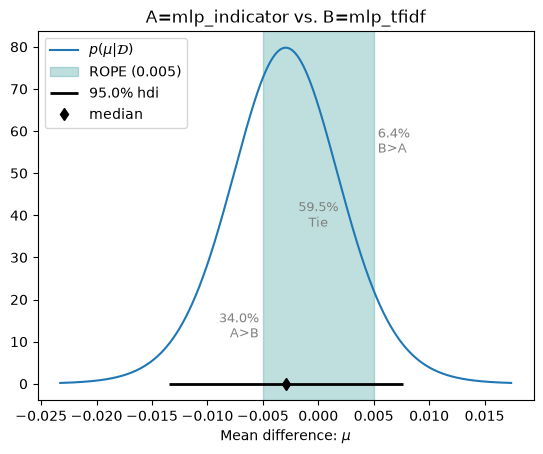

mlp_indicator vs mlp_bow: P(best better)=0.644  P(practically equal)=0.345  P(other better)=0.011


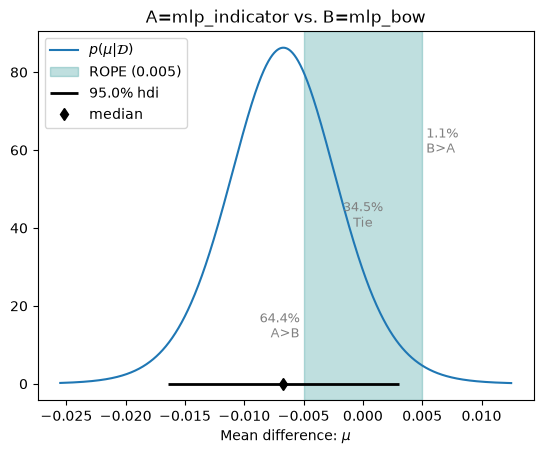

In [15]:
# Posteriors of the best system vs its two closest competitors, with the ROPE (for the slides)
BEST = "mlp_indicator"

for other in ["mlp_tfidf", "mlp_bow"]:
    acc_best = get_all_measurements_for(my_classifiers, BEST)
    acc_other = get_all_measurements_for(my_classifiers, other)

    posterior = part1.analysis.BenavoliCorrelatedT(
        acc_best.flatten(), acc_other.flatten(),
        runs=acc_best.shape[0],            # number of seeds
        names=[BEST, other]
    )
    p_best, p_tie, p_other = posterior.probs(0.005)
    print(f"{BEST} vs {other}: P(best better)={p_best:.3f}  "
          f"P(practically equal)={p_tie:.3f}  P(other better)={p_other:.3f}")
    _ = posterior.plot(0.005)
    plt.show()

System: mlp_indicator
Accuracy over all validation folds and seeds: 0.5586 (should be ≈ the mean accuracy in the 3x3 table)

              precision    recall  f1-score   support

         joy      0.662     0.700     0.680      2631
        fear      0.674     0.674     0.674      2604
       anger      0.463     0.445     0.454      2544
     sadness      0.598     0.590     0.594      2574
     disgust      0.570     0.562     0.566      2535
       shame      0.467     0.443     0.454      2589
       guilt      0.464     0.492     0.478      2559

    accuracy                          0.559     18036
   macro avg      0.557     0.558     0.557     18036
weighted avg      0.557     0.559     0.558     18036



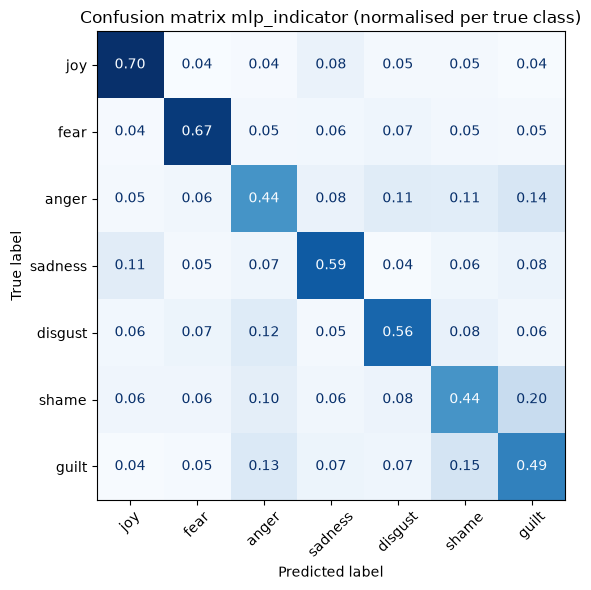

Most confused pairs (errors summed over 3 seeds):
     shame <-> guilt    896 errors
     anger <-> guilt    693 errors
     anger <-> disgust  592 errors
     anger <-> shame    533 errors
       joy <-> sadness  493 errors

Example errors between shame and guilt:
- true: guilt    predicted: shame   
  I forgot to convey an important announcement.

- true: guilt    predicted: shame   
  It was when I discovered that the girl who I had proposed was a friend's girlfriend.

- true: guilt    predicted: shame   
  During 7th grade our class mobbed a famale teacher so badly that she had a breackdown and was hospitalized.

- true: guilt    predicted: shame   
  Getting a friend an open container ticket because I got caught speeding.

- true: shame    predicted: guilt   
  I feel shy to show all my worth when I work for the first time with a conductor or a producer unfamiliar to me.



In [13]:
# Error analysis of the best system, using its own cross-validation predictions
# (generated with help of Claude, see documentation.md for AI use)

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, classification_report, accuracy_score

SEEDS = (0, 1, 2)   # must be the same seeds as in run_experiments
N_FOLDS = 5


def collect_cv_predictions(data, sys_name, pairs, seeds=SEEDS, num_folds=N_FOLDS):
    """Gold labels, predictions and text ids over all validation folds of all seeds."""
    y_true, y_pred, text_ids = [], [], []
    for seed, run in zip(seeds, data[sys_name]):
        # recreate exactly the same split as during training
        cv = part1.experiment.cross_validation_split(pairs, k=num_folds, seed=seed)
        for fold, split in cv.items():
            preds = [int(p) for p in run["predictions"][fold]]
            gold = [label for _, label in split["validation"]]
            assert len(preds) == len(gold), "predictions and validation set do not match"
            y_true += gold
            y_pred += preds
            text_ids += [int(i) for i in split["validation_ids"]]
    return np.array(y_true), np.array(y_pred), np.array(text_ids)


def error_analysis(data, sys_name, pairs, outcome_space, n_examples=5):
    n_classes = len(outcome_space)
    names = [outcome_space.name(i) for i in range(n_classes)]
    labels = list(range(n_classes))

    y_true, y_pred, text_ids = collect_cv_predictions(data, sys_name, pairs)

    print(f"System: {sys_name}")
    print(f"Accuracy over all validation folds and seeds: {accuracy_score(y_true, y_pred):.4f} "
          f"(should be ≈ the mean accuracy in the 3x3 table)\n")

    # 1. Scores per class
    print(classification_report(y_true, y_pred, labels=labels, target_names=names, digits=3))

    # 2. Confusion matrix, normalised per row: "of the texts with true emotion X, which share was predicted as Y?"
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, labels=labels, display_labels=names,
        normalize="true", values_format=".2f", cmap="Blues", ax=ax, colorbar=False
    )
    ax.set_title(f"Confusion matrix {sys_name} (normalised per true class)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    # 3. Which pairs are confused most often (both directions together)?
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    confused = sorted(
        ((cm[i, j] + cm[j, i], i, j) for i in range(n_classes) for j in range(i + 1, n_classes)),
        reverse=True
    )
    print(f"Most confused pairs (errors summed over {len(SEEDS)} seeds):")
    for count, i, j in confused[:5]:
        print(f"  {names[i]:>8} <-> {names[j]:<8} {count} errors")

    # 4. Example errors for the most confused pair
    _, i, j = confused[0]
    mask = ((y_true == i) & (y_pred == j)) | ((y_true == j) & (y_pred == i))
    print(f"\nExample errors between {names[i]} and {names[j]}:")
    shown = set()
    for k in np.where(mask)[0]:
        if text_ids[k] in shown:          # the same text can appear once per seed
            continue
        shown.add(text_ids[k])
        text = " ".join(pairs[text_ids[k]][0].split())
        print(f"- true: {names[y_true[k]]:<8} predicted: {names[y_pred[k]]:<8}\n  {text}\n")
        if len(shown) == n_examples:
            break

    return {"cm": cm, "y_true": y_true, "y_pred": y_pred, "text_ids": text_ids}


best_system = max(my_classifiers, key=lambda s: get_all_measurements_for(my_classifiers, s).mean())
error_results = error_analysis(my_classifiers, best_system, pairs, outcome_space)